# ML Assignment 4 - Gradient descent to find the local minimum of a function

**Problem statement:** implement gradient descent to minimise y = (x + 3)^2 starting from x = 2. Each step moves against the gradient dy/dx = 2(x + 3): `x_new = x - learning_rate * gradient`, until the step is tiny. The true minimum is at x = -3.

**Libraries used:** numpy and matplotlib (plotting only); the algorithm itself is plain Python.

**Driver:** starts at x = 2 with learning rate 0.1, then shows the effect of other learning rates. No input is taken at runtime.

In [1]:
import numpy as np
import matplotlib.pyplot as plt


def f(x):
    return (x + 3) ** 2


def gradient(x):
    return 2 * (x + 3)  # derivative of (x + 3)^2

## 1. The algorithm

In [2]:
def gradient_descent(start, learning_rate, tolerance=1e-6, max_iter=1000):
    x, history = start, [start]
    for _ in range(max_iter):
        step = learning_rate * gradient(x)
        if abs(step) < tolerance:  # converged: moves are negligible
            break
        x -= step
        history.append(x)
    return x, history

## 2. Run from x = 2 with learning rate 0.1

 iter            x            y     gradient
    0     2.000000    25.000000    10.000000
    1     1.000000    16.000000     8.000000
    2     0.200000    10.240000     6.400000
    3    -0.440000     6.553600     5.120000
    4    -0.952000     4.194304     4.096000
    5    -1.361600     2.684355     3.276800
  ...
Converged after 62 iterations: x = -2.999995, y = 2.40e-11  (true minimum at x = -3)


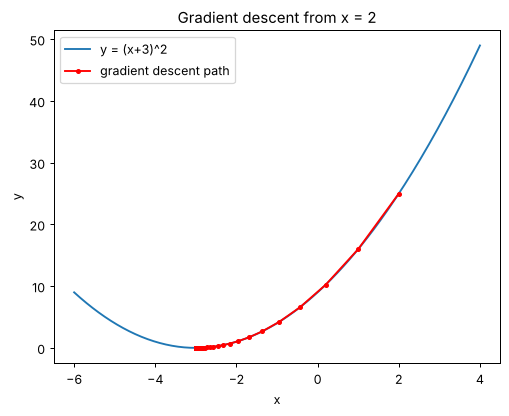

In [3]:
x_min, history = gradient_descent(start=2, learning_rate=0.1)
print(f"{'iter':>5} {'x':>12} {'y':>12} {'gradient':>12}")
for i, x in enumerate(history[:6]):
    print(f"{i:>5} {x:>12.6f} {f(x):>12.6f} {gradient(x):>12.6f}")
print("  ...")
print(f"Converged after {len(history) - 1} iterations: x = {x_min:.6f}, y = {f(x_min):.2e}  (true minimum at x = -3)")

xs = np.linspace(-6, 4, 200)
plt.plot(xs, f(xs), label="y = (x+3)^2")
plt.plot(history, [f(x) for x in history], "o-", color="red", markersize=3, label="gradient descent path")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.title("Gradient descent from x = 2")

## 3. Effect of the learning rate
Too small is slow, a moderate rate converges quickly, and a rate above 1 overshoots further each step and diverges.

In [4]:
for lr in (0.01, 0.1, 0.9, 1.1):
    x, hist = gradient_descent(2, lr, max_iter=200)
    status = "diverges" if abs(x) > 1e6 else f"x = {x:.4f}"
    print(f"learning rate {lr:<5} -> {len(hist) - 1:>3} iterations, {status}")

learning rate 0.01  -> 200 iterations, x = -2.9121
learning rate 0.1   ->  62 iterations, x = -3.0000
learning rate 0.9   ->  72 iterations, x = -3.0000
learning rate 1.1   -> 200 iterations, diverges


**Conclusion:** gradient descent reaches the minimum x = -3 for a suitable learning rate. The learning rate controls the step length: too small is slow, too large overshoots and may diverge.